# Hyperparameter Tuning in scikit-learn


A model learns parameters such as coefficients or tree splits from the training data. Hyperparameters are different: they are choices we make before training, and they influence how the learning process behaves.

In this notebook, we compare three common tuning strategies for a logistic regression classifier: `RandomizedSearchCV`, `GridSearchCV`, and [Optuna](https://optuna.org/).


The overall workflow looks like this:

```mermaid
flowchart LR
    A[Choose a model] --> B[Define a hyperparameter search space]
    B --> C[Evaluate settings with cross-validation]
    C --> D[Pick the best configuration]
    D --> E[Test once on held-out data]
```


## What Counts as a Hyperparameter?


For logistic regression, examples of hyperparameters include:

- the regularization strength `C`,
- the regularization mix `l1_ratio`, where `0` gives an `l2` penalty and `1` gives an `l1` penalty,
- the solver used by the optimizer,
- whether class imbalance is handled with `class_weight="balanced"`.

Scikit-learn estimators expose these choices through `get_params()`.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
pd.Series(LogisticRegression().get_params()).sort_index()

C                           1.0
class_weight               None
dual                      False
fit_intercept              True
intercept_scaling             1
l1_ratio                    0.0
max_iter                    100
n_jobs                     None
penalty              deprecated
random_state               None
solver                    lbfgs
tol                      0.0001
verbose                       0
warm_start                False
dtype: object

## Why Cross-Validation Matters


If we evaluate only one train-test split, the result can be unusually lucky or unlucky. Cross-validation reduces that risk by repeating the training and validation process across several folds and averaging the results.

That makes it a natural foundation for hyperparameter tuning.


## Build a Baseline Pipeline


We reuse the water-quality dataset. Because the target is imbalanced, we use F1 score instead of accuracy so that false positives and false negatives both matter in the evaluation.


In [3]:
df = pd.read_csv("data/water-quality.csv")
df.head()

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1


In [4]:
df["is_safe"].value_counts()

is_safe
0    7084
1     912
Name: count, dtype: int64

We scale the features inside a `Pipeline` so that cross-validation handles preprocessing correctly within each fold. This avoids data leakage and keeps the tuning workflow clean.


In [5]:
X = df.drop(columns="is_safe")
y = df["is_safe"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y,
)

baseline_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                solver="liblinear",
                max_iter=2000,
                random_state=1,
            ),
        ),
    ]
)

baseline_pipeline.fit(X_train, y_train)
baseline_test_f1 = f1_score(y_test, baseline_pipeline.predict(X_test))
baseline_cv_f1 = cross_val_score(
    baseline_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="f1",
    n_jobs=-1,
).mean()

print(f"Baseline CV F1: {baseline_cv_f1:.3f}")
print(f"Baseline test F1: {baseline_test_f1:.3f}")

Baseline CV F1: 0.451
Baseline test F1: 0.451


The baseline gives us a reference point. Now we can ask whether tuning the hyperparameters improves the model.


## RandomizedSearchCV


`RandomizedSearchCV` samples a limited number of parameter combinations from the search space. It is often a good first step because it is usually much faster than evaluating every possible combination.


In [6]:
random_search_space = {
    "model__C": np.logspace(-3, 2, 20),
    "model__l1_ratio": [0, 1],
    "model__class_weight": [None, "balanced"],
}

random_search = RandomizedSearchCV(
    estimator=baseline_pipeline,
    param_distributions=random_search_space,
    n_iter=10,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    random_state=1,
)

random_search.fit(X_train, y_train)

random_test_f1 = f1_score(y_test, random_search.best_estimator_.predict(X_test))

print("Best parameters:", random_search.best_params_)
print(f"Best CV F1: {random_search.best_score_:.3f}")
print(f"Test F1: {random_test_f1:.3f}")

Best parameters: {'model__l1_ratio': 0, 'model__class_weight': 'balanced', 'model__C': np.float64(54.555947811685144)}
Best CV F1: 0.465
Test F1: 0.464


## GridSearchCV


`GridSearchCV` evaluates every combination in a predefined grid. It is more exhaustive than randomized search, but its cost grows quickly as the grid becomes larger.


In [7]:
grid_search_space = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__l1_ratio": [0, 1],
    "model__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    estimator=baseline_pipeline,
    param_grid=grid_search_space,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)

grid_test_f1 = f1_score(y_test, grid_search.best_estimator_.predict(X_test))

print("Best parameters:", grid_search.best_params_)
print(f"Best CV F1: {grid_search.best_score_:.3f}")
print(f"Test F1: {grid_test_f1:.3f}")

Best parameters: {'model__C': 10, 'model__class_weight': 'balanced', 'model__l1_ratio': 0}
Best CV F1: 0.465
Test F1: 0.464


It is often useful to inspect more than just the single best result. The table below shows the top grid-search configurations and how close their cross-validation scores are.

In [8]:
pd.DataFrame(grid_search.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values(["rank_test_score", "mean_test_score"], ascending=[True, False]).head()

,params,mean_test_score,std_test_score,rank_test_score
14,"{'model__C': 10, 'model__class_weight': 'balan...",0.465241,0.017599,1
15,"{'model__C': 10, 'model__class_weight': 'balan...",0.464770,0.018051,2
10,"{'model__C': 1, 'model__class_weight': 'balanc...",0.464552,0.018067,3
7,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.464009,0.019715,4
11,"{'model__C': 1, 'model__class_weight': 'balanc...",0.463889,0.018303,5


## Optuna


Optuna is a more flexible optimization framework. Instead of exhaustively checking a grid, it chooses the next trial based on what earlier trials have already discovered.

That makes it especially useful when the search space is large or includes continuous parameters.


In [9]:
def objective(trial):
    pipeline = Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    C=trial.suggest_float("C", 1e-3, 1e2, log=True),
                    l1_ratio=trial.suggest_categorical("l1_ratio", [0, 1]),
                    class_weight=trial.suggest_categorical(
                        "class_weight",
                        [None, "balanced"],
                    ),
                    solver="liblinear",
                    max_iter=2000,
                    random_state=1,
                ),
            ),
        ]
    )

    return cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="f1",
        n_jobs=-1,
    ).mean()


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20)

optuna_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                **study.best_params,
                solver="liblinear",
                max_iter=2000,
                random_state=1,
            ),
        ),
    ]
)

optuna_pipeline.fit(X_train, y_train)
optuna_test_f1 = f1_score(y_test, optuna_pipeline.predict(X_test))

print("Best parameters:", study.best_params)
print(f"Best CV F1: {study.best_value:.3f}")
print(f"Test F1: {optuna_test_f1:.3f}")

Best parameters: {'C': 60.81759387521923, 'l1_ratio': 1, 'class_weight': 'balanced'}
Best CV F1: 0.465
Test F1: 0.464


## Compare the Tuning Methods


In [10]:
comparison_df = pd.DataFrame(
    {
        "approach": [
            "Baseline pipeline",
            "RandomizedSearchCV",
            "GridSearchCV",
            "Optuna",
        ],
        "cv_f1": [
            baseline_cv_f1,
            random_search.best_score_,
            grid_search.best_score_,
            study.best_value,
        ],
        "test_f1": [
            baseline_test_f1,
            random_test_f1,
            grid_test_f1,
            optuna_test_f1,
        ],
    }
).sort_values("test_f1", ascending=False)

comparison_df

,approach,cv_f1,test_f1
1,RandomizedSearchCV,0.465241,0.464430
2,GridSearchCV,0.465241,0.464430
3,Optuna,0.465241,0.464430
0,Baseline pipeline,0.450919,0.451039


A small comparison chart makes the overall result easier to interpret at a glance. It shows whether the tuned methods meaningfully outperform the baseline and whether the cross-validation trend matches the held-out test result.


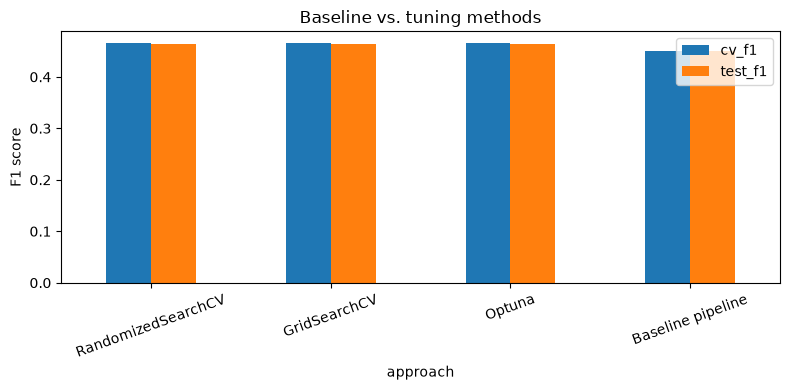

In [11]:
comparison_df.plot(
    x="approach",
    y=["cv_f1", "test_f1"],
    kind="bar",
    figsize=(8, 4),
)
plt.ylabel("F1 score")
plt.title("Baseline vs. tuning methods")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Hyperparameter tuning can improve a model, but it is not magic. The gains may be small if the baseline is already strong, and the more exhaustive the search, the more computation it costs. In practice, randomized search is often a great first pass, grid search is useful for small focused grids, and Optuna is especially attractive when the search space is larger or more flexible.


## Optional Optuna Visualizations


Optuna also provides built-in visualizations that help explain which parameters mattered most and how the optimization progressed.


In [12]:
import optuna.visualization as ov

ov.plot_param_importances(study)

In [13]:
ov.plot_optimization_history(study)